## Embedding Adjustment Notebook (Alternate approach using triplet learning)

This will contain the model to adjust the embedding space in some way to accurately represent user inputs.

Current plan is to use a Neural Network from PyTorch to alter the values of the embeddings to other embeddings with the exact same shape. Building the network is easy, but figuring out the loss function is harder.

In [1]:
%pip install torch numpy scikit-learn matplotlib notebook

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/8.2 MB ? eta -:--:--
   -------------- ------------------------- 2.9/8.2 MB 15.9 MB/s eta 0:00:01
   ------------------------------- -------- 6.6/8.2 MB 17.6 MB/s eta 0:00:01
   ---------------------------------------- 8.2/8.2 MB 17.1 MB/s  0:00:00

   ---------- ----------------------------- 1/4 [narwhals]
   ---------- ----------------------------- 1/4 [narwhals]
   ---------- ----------------------------- 1/4 [narwhals]
   -------------------- ------------------- 2/4 [joblib]
   -------------------- ------------------- 2/4 [joblib]
   ------------------------------ --------- 3/4 [scikit-learn]
   ------------------------------ --------- 3/4 [scikit-learn]
   ------------------------------ --------- 3/4 [scikit-learn]
   ------------------------------ --------- 3/4 [scikit-learn]
   ------------------------------ --------- 3/4 [scikit-learn]
   ---------------


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: C:\Users\jaych\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [40]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.metrics import adjusted_rand_score
from sklearn.preprocessing import normalize

from clustering import cluster_embeddings

# For experimenting with reproducibility
seed = 123

## Neural Network

This section contains the Neural Network that adjusts the embeddings. This sets up the architecture and tests forward with just basic inputs.

In [27]:
# Architecture of the model (can change)
class Net(nn.Module):

    def __init__(self, dimensions: int, hidden_size: int = 256, scaling_factor: float=0.1):
        super(Net, self).__init__()
        self.dimensions = dimensions
        self.layer1 = nn.Linear(dimensions, hidden_size)
        self.layer2 = nn.Linear(hidden_size, dimensions)
        self.scaling_factor = scaling_factor

        nn.init.zeros_(self.layer1.bias)
        nn.init.zeros_(self.layer2.bias)

    def forward(self, x):
        x_adj = self.layer1(x)
        x_adj = F.relu(x_adj)
        x_adj = self.layer2(x_adj)
        # Added a residual connection with a scaling factor (we can experiment with different scaling factors to see what works best) so that original input gets preserved
        out = x + self.scaling_factor * F.sigmoid(x_adj)
        return F.normalize(out, p=2, dim=1)

In [28]:
example_model = Net(dimensions=1024)
example_inputs = torch.randn(5, 1024)
example_outputs = example_model(example_inputs)
print("Inputs:", tuple(example_inputs.shape), "Outputs:", tuple(example_outputs.shape))
assert example_inputs.shape == example_outputs.shape

Inputs: (5, 1024) Outputs: (5, 1024)


## Embeddings + Initial Clustering

In [ ]:
use_real_embeddings = False
embeddings_path = "" # Wherever the pokemen embeddings are stored would go here
n = 3

if use_real_embeddings:
    embeddings = np.load(embeddings_path)
else:
    embeddings, _unused_hidden_labels = make_blobs(
        n_samples=90,
        centers=n,
        n_features=24,
        cluster_std=2.5,
        random_state=seed
    )

embeddings = np.asarray(embeddings, dtype=np.float32)

# Validation checks
if embeddings.ndim != 2 or not np.isfinite(embeddings).all():
    print("embeddings are not a 2D array or contains non-finite numbers")
if not 2 <= n < len(embeddings):
    print("Invalid number of clusters (n)")
if np.any(np.linalg.norm(embeddings, axis=1) == 0):
    print("No embedding found")

embeddings = normalize(embeddings, norm="l2").astype(np.float32)

# Can change algorithm = "kmeans" or "dbscan" or "hierarchial" or "spectral". Planning on adding a meta clustering soon
initial_labels, initial_cluster_model = cluster_embeddings(embeddings, algorithm="kmeans", n_clusters=n, random_state=seed)

print("Embeddings:", embeddings.shape)
print("Cluster IDs are arbitrary:", np.unique(initial_labels))
print("Cluster sizes:", np.bincount(initial_labels))

Embeddings: (90, 24)
Cluster IDs are arbitrary: [0 1 2]
Cluster sizes: [30 30 30]


## Loss Function

This contains how we calculate loss. 

Using the loss function: $$L_{triplet} = \max(0, \|f(A)-f(P)\|_2-\|f(A)-f(N)\|_2+m)$$

where margin = m, which is saying that the anchor (A) should be at least m closer to the positive (P) than to the negative (N).

In [30]:
def triplets_from_move(cluster_labels, moved_item, destination_cluster, num_triplets=32):

    labels = np.asarray(cluster_labels)

    # Validation checks
    if labels.ndim != 1:
        print("cluster_labels must be a 1D array")
    if not 0 <= moved_item < len(labels):
        print("moved_item is out of range")
    if num_triplets <= 0:
        print("num_triplets must be positive")

    old_cluster = labels[moved_item]
    if old_cluster == destination_cluster:
        print("The destination must differ from the original cluster")

    positive_indices = np.flatnonzero(labels == destination_cluster)
    negative_indices = np.flatnonzero(labels == old_cluster)
    negative_indices = negative_indices[negative_indices != moved_item]

    if len(positive_indices) == 0 or len(negative_indices) == 0:
        print("Need positive examples in destination and other items in old cluster")

    rng = np.random.default_rng(seed)
    return [(int(moved_item), int(rng.choice(positive_indices)), int(rng.choice(negative_indices))) for _ in range(num_triplets)]

In [31]:
# Simulatation of 1 move
moved_item = int(np.flatnonzero(initial_labels == 0)[0])
source_cluster = int(initial_labels[moved_item])
destination_cluster = int(next(c for c in np.unique(initial_labels) if c != source_cluster))

feedback_triplets = triplets_from_move(initial_labels, moved_item, destination_cluster, num_triplets=32)

user_edited_labels = initial_labels.copy()
user_edited_labels[moved_item] = destination_cluster
user_specified = np.zeros(len(embeddings), dtype=bool)
user_specified[moved_item] = True

print(f"User moved item {moved_item} from cluster {source_cluster} to {destination_cluster}")
print("First 5 (anchor, positive, negative) indices:", feedback_triplets[:5])
print("Number of distinct human edits: 1; sampled triplets:", len(feedback_triplets))

User moved item 0 from cluster 0 to 1
First 5 (anchor, positive, negative) indices: [(0, 1, 57), (0, 50, 7), (0, 83, 25), (0, 22, 20), (0, 28, 20)]
Number of distinct human edits: 1; sampled triplets: 32


## Data Preparation

This section contains the necessary pre-processing done on the data

In [32]:
# Turn into triplets
class TripletDataset(Dataset):
    def __init__(self, inputs, triplets):
        self.inputs = torch.as_tensor(inputs, dtype=torch.float32)
        self.triplets = torch.as_tensor(triplets, dtype=torch.long)
        if self.triplets.ndim != 2 or self.triplets.shape[1] != 3 or len(self.triplets) == 0:
            print("triplets must be nonempty and have shape (num_triplets, 3)")
        if self.triplets.min() < 0 or self.triplets.max() >= len(self.inputs):
            print("A triplet index does not match an embedding row")

    def __len__(self):
        return len(self.triplets)

    def __getitem__(self, idx):
        a, p, n = self.triplets[idx]
        return self.inputs[a], self.inputs[p], self.inputs[n]

In [33]:
def load_data(inputs, triplets, batch_size):
    train_set = TripletDataset(inputs, triplets)
    train_dataloader = DataLoader(train_set, batch_size=batch_size, shuffle=True)

    return train_dataloader

## NN Training

This will train the network with the loss function defined above, way unfinished

In [ ]:
def train_loop(data, epochs, loss_function, optimizer, batch_size, model,preservation_weight=0.05):
    original_embeddings, triplet_indices = data
    train_dataloader = load_data(original_embeddings, triplet_indices, batch_size)
    loss_history = []

    for epoch in range(1, epochs + 1):
        model.train()
        epoch_losses = []

        for anchor, positive, negative in train_dataloader:

            optimizer.zero_grad()
            anchor_out = model(anchor)
            positive_out = model(positive)
            negative_out = model(negative)

            triplet_loss = loss_function(anchor_out, positive_out, negative_out)

            originals = torch.cat((anchor, positive, negative), dim=0)
            transformed = torch.cat((anchor_out, positive_out, negative_out), dim=0)
            preservation_loss = F.mse_loss(transformed, F.normalize(originals, p=2, dim=1))
            loss = triplet_loss + preservation_weight * preservation_loss

            loss.backward()
            optimizer.step()
            epoch_losses.append(loss.item())

        loss_history.append(float(np.mean(epoch_losses)))
        if epoch == 1 or epoch % 20 == 0 or epoch == epochs:
            print(f"Epoch {epoch:3d}/{epochs}: mean total loss = {loss_history[-1]:.5f}")

    return loss_history


def transform_all(model, original_embeddings, batch_size=256):
    model.eval()
    tensor = torch.as_tensor(original_embeddings, dtype=torch.float32)
    chunks = []
    with torch.no_grad():
        for chunk in tensor.split(batch_size):
            chunks.append(model(chunk).cpu().numpy())
    return np.concatenate(chunks, axis=0)

## Pipeline

This section has the instructions to run the full pipeline from above

format the data like this
a 3-tuple containing tensors with the following shapes ([n, 1024], [n], [n]) where n is the number of samples

The first one is the embeddings of each datapoint

the second one is the id of the cluster they were assigned to

the third is full of 1 or 0, 1 if it was a user-specified input, 0 else

Then specify number of epochs

a loss function from above

and an optimizer

In [ ]:
model = Net(dimensions=embeddings.shape[1], hidden_size=256, scaling_factor=0.1)
loss_function = nn.TripletMarginLoss(margin=0.2, p=2)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

before_embeddings = transform_all(model, embeddings)
loss_history = train_loop(
    data=(embeddings, feedback_triplets),
    epochs=100,
    loss_function=loss_function,
    optimizer=optimizer,
    batch_size=16,
    model=model,
    preservation_weight=0.05,
)
after_embeddings = transform_all(model, embeddings)

print("Output shape:", after_embeddings.shape)

Epoch   1/100: mean total loss = 1.18659
Epoch  20/100: mean total loss = 1.03312
Epoch  40/100: mean total loss = 0.89758
Epoch  60/100: mean total loss = 0.87664
Epoch  80/100: mean total loss = 0.84222
Epoch 100/100: mean total loss = 0.79386
Output shape: (90, 24)


## Evaluation

### Metrics:
- Mean Anchor-Positive Distance: Average distance between items the user wants together (Want small)
- Mean Anchor-Negative Distance: Average distance between items the user wants separated (Want large)
- Mean Triplet Violation: Average amount by which triplets fail the margin condition (Want close to 0)
- Fraction Satisfying Triplet: Proportion of triplets satisfying the margin (Want close to 1)

BEFORE {'mean anchor-positive distance': 1.5499117374420166, 'mean anchor-negative distance': 0.5623763799667358, 'mean triplet violation': 1.1875354051589966, 'fraction satisfying triplet': 0.0}
AFTER  {'mean anchor-positive distance': 1.32511568069458, 'mean anchor-negative distance': 0.7328778505325317, 'mean triplet violation': 0.7922378182411194, 'fraction satisfying triplet': 0.0}


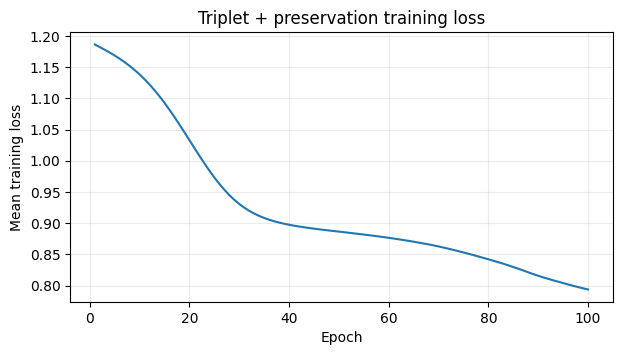

In [ ]:
def triplet_metrics(all_embeddings, triplets, margin=0.2):
    ids = np.asarray(triplets, dtype=np.int64)
    a = all_embeddings[ids[:, 0]]
    p = all_embeddings[ids[:, 1]]
    n = all_embeddings[ids[:, 2]]
    # Calculate euclidean distances for each triplet
    positive_distance = np.linalg.norm(a - p, axis=1)
    negative_distance = np.linalg.norm(a - n, axis=1)
    violation = np.maximum(0, positive_distance - negative_distance + margin)
    return {
        "mean anchor-positive distance": float(np.mean(positive_distance)),
        "mean anchor-negative distance": float(np.mean(negative_distance)),
        "mean triplet violation": float(np.mean(violation)),
        "fraction satisfying triplet": float(np.mean(violation <= 1e-6)),
    }

print("BEFORE", triplet_metrics(before_embeddings, feedback_triplets))
print("AFTER ", triplet_metrics(after_embeddings, feedback_triplets))

plt.figure(figsize=(7, 3.5))
plt.plot(np.arange(1, len(loss_history) + 1), loss_history)
plt.xlabel("Epoch")
plt.ylabel("Mean training loss")
plt.title("Triplet + preservation training loss")
plt.grid(alpha=0.25)
plt.show()

## Reclustering

In [41]:
new_labels, new_cluster_model = cluster_embeddings(after_embeddings, algorithm="kmeans", n_clusters=n, random_state=seed)

print("Cluster sizes before:", np.bincount(initial_labels))
print("Cluster sizes after: ", np.bincount(new_labels))
print("Partition similarity (ARI before vs after):", round(adjusted_rand_score(initial_labels, new_labels), 4))
print("Moved item:", moved_item)
print("Initial predicted cluster:", initial_labels[moved_item])
print("New predicted cluster:", new_labels[moved_item], "(IDs can be permuted!)")

positive_examples = np.unique(np.asarray(feedback_triplets)[:, 1])
pre_share = np.mean(initial_labels[positive_examples] == initial_labels[moved_item])
post_share = np.mean(new_labels[positive_examples] == new_labels[moved_item])
print(f"Fraction of selected destination examples grouped with moved item: {pre_share:.3f} -> {post_share:.3f}")

Cluster sizes before: [30 30 30]
Cluster sizes after:  [30 30 30]
Partition similarity (ARI before vs after): 1.0
Moved item: 0
Initial predicted cluster: 0
New predicted cluster: 0 (IDs can be permuted!)
Fraction of selected destination examples grouped with moved item: 0.000 -> 0.000


# Save the trained model + transformed embeddings

this creates **embedding_transform.pt** which stores the trained neural network and **personalized_embeddings.npy** which stores the transformed embedding vectors

In [43]:
from pathlib import Path

output_dir = Path("triplet_outputs")
output_dir.mkdir(exist_ok=True)

np.save(output_dir / "personalized_embeddings.npy", after_embeddings)
torch.save({
    "input_dim": int(embeddings.shape[1]),
    "hidden_size": 256,
    "adjustment_scale": 0.1,
    "model_state_dict": model.cpu().state_dict(),
}, output_dir / "embedding_transform.pt")

print("Saved model and embeddings in:", output_dir.resolve())

Saved model and embeddings in: C:\Users\jaych\Downloads\alternate_pipeline\triplet_outputs


### Use this code to use the trained model/transformed embeddings:

trained_model = torch.load("triplet_outputs/embedding_transform.pt")

model = Net(dimensions=trained_model["input_dim"], hidden_size=trained_model["hidden_size"], scaling_factor=trained_model["adjustment_scale"])

model.load_state_dict(checkpoint["model_state_dict"])

model.eval()